# Customer Churn Analysis for a Telecommunications Company
## Customer Segmentation Using K-Means Clustering

### Data Analyst – Clustering Analysis



In [1]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import library for visualisation
import matplotlib.pyplot as plt

# Import preprocessing and clustering tools
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

# Import clustering evaluation metric
from sklearn.metrics import silhouette_score

# Improve table display in Colab
pd.set_option('display.max_columns', None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Telecommunications Customer Dataset

The dataset of telecommunications customers is uploaded to Google Colab and loaded into a Pandas DataFrame to be analyzed.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Dataset_ATS_v2.csv to Dataset_ATS_v2.csv


In [3]:
# Automatically obtain the uploaded filename
file_name = next(iter(uploaded))

# Load the CSV dataset
df = pd.read_csv(file_name)

print("Dataset loaded successfully.")
print("Filename:", file_name)

Dataset loaded successfully.
Filename: Dataset_ATS_v2.csv


## 3. Initial Dataset Inspection

The data is analyzed to determine the structure of the data set, and then clusters are defined. This involves checking sample records, dimensions of the data set, column names and data types.


In [4]:
# Display the first five records
df.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


In [5]:
 # Display the number of rows and columns
print("Number of customers:", df.shape[0])
print("Number of variables:", df.shape[1])

Number of customers: 7043
Number of variables: 10


In [6]:
# Display all column names
print("Dataset columns:")

for column in df.columns:
    print("-", column)

Dataset columns:
- gender
- SeniorCitizen
- Dependents
- tenure
- PhoneService
- MultipleLines
- InternetService
- Contract
- MonthlyCharges
- Churn


In [7]:
# Review data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   gender           7043 non-null   object
 1   SeniorCitizen    7043 non-null   int64 
 2   Dependents       7043 non-null   object
 3   tenure           7043 non-null   int64 
 4   PhoneService     7043 non-null   object
 5   MultipleLines    7043 non-null   object
 6   InternetService  7043 non-null   object
 7   Contract         7043 non-null   object
 8   MonthlyCharges   7043 non-null   int64 
 9   Churn            7043 non-null   object
dtypes: int64(3), object(7)
memory usage: 550.4+ KB


### Initial Dataset Interpretation

The data set has 7,043 customer records and 10 variables. Tenure and MonthlyCharges are two variables that are already numeric, and don't need to be converted. Thus, when using K-Means model, categorical encoding is not needed since the project specifically asks for the customers to be grouped based on tenures and monthly charges.


## 4. Data Quality and Integrity Assessment

The data set is examined for inconsistencies, repeated records and missing data prior to clustering. A validation of data quality is required as the clustering based on distance may be influenced by inaccurate and incomplete observations.


In [8]:
# Count missing values in every column
missing_values = df.isnull().sum()

print("Missing values by variable:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values by variable:
gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64

Total missing values: 0


### Missing Data Interpretation

No data was missing from the data set. Thus there were no observation values needing to be removed or imputed prior to clustering.


In [9]:
# Check for rows that contain exactly the same values across all available variables
exact_repeated_rows = df.duplicated().sum()

print("Number of exact repeated rows:", exact_repeated_rows)

Number of exact repeated rows: 302


## 5. Descriptive Analysis of Clustering Variables



In [10]:
# Descriptive statistics for the required clustering variables
df[['tenure', 'MonthlyCharges']].describe().round(2)

,tenure,MonthlyCharges
count,7043.00,7043.00
mean,32.37,64.76
std,24.56,30.09
min,0.00,18.00
25%,9.00,36.00
50%,29.00,70.00
75%,55.00,90.00
max,72.00,119.00


### Descriptive Interpretation

The tenure of the customers vary between 0 to 72 months with the average being around 32.37 months. The monthly charge is in the range of 18-119 with an average of about 64.76.



## 6. Outlier Assessment

The Interquartile Range (IQR) method is used to investigate potential extreme observations. K-Means clustering can be affected by significant outliers.


In [11]:
# Function to identify potential outliers using the IQR method
def iqr_outlier_count(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"{column}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")
    print()

iqr_outlier_count(df, 'tenure')
iqr_outlier_count(df, 'MonthlyCharges')

tenure
Lower bound: -60.00
Upper bound: 124.00
Potential outliers: 0

MonthlyCharges
Lower bound: -45.00
Upper bound: 171.00
Potential outliers: 0



### Outlier Interpretation

No statistical outliers were found in the data for either tenure or monthly charges using the 1.5 × IQR rule. So, it was not necessary to remove or cap observations in this stage of pre-processing.


## 7. Exploratory Visualisation

Prior to customer segmentation, the distributions and relationship between tenure and monthly charges are visualised.


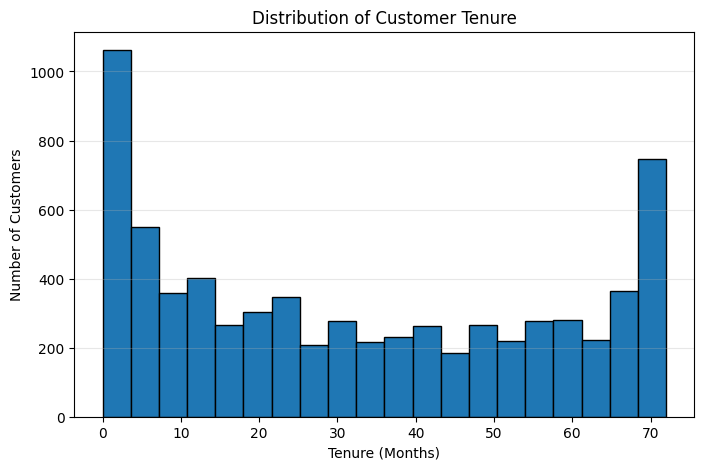

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df['tenure'], bins=20, edgecolor='black')

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.grid(axis='y', alpha=0.3)
plt.show()

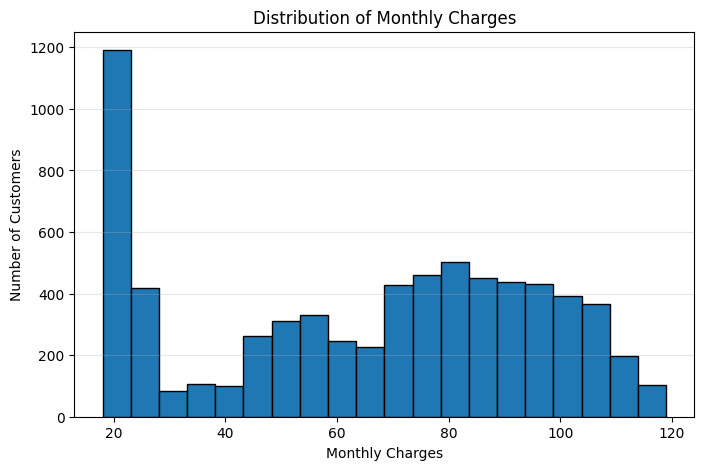

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(df['MonthlyCharges'], bins=20, edgecolor='black')

plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.grid(axis='y', alpha=0.3)
plt.show()

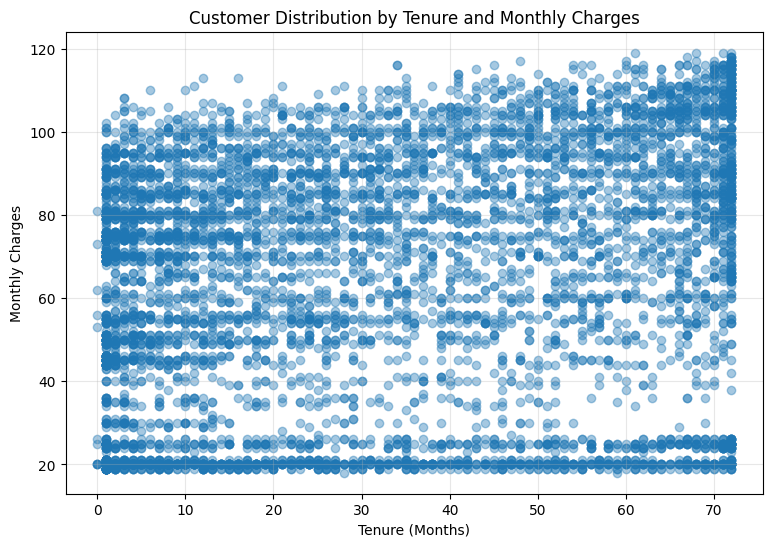

In [15]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df['tenure'],
    df['MonthlyCharges'],
    alpha=0.4
)

plt.title('Customer Distribution by Tenure and Monthly Charges')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')

plt.grid(alpha=0.3)
plt.show()

In [16]:
correlation = df[['tenure', 'MonthlyCharges']].corr()

correlation

,tenure,MonthlyCharges
tenure,1.000000,0.247853
MonthlyCharges,0.247853,1.000000


### Exploratory Analysis Interpretation

The scatter plot shows that there is a lot of variation in both charges per month and tenure of the customer, so there may be several different customer profiles.

There is a slight positive relationship between tenure and the monthly charges, with a correlation of about 0.25.

## 8. Selection of Clustering Features

The K-Means model will perform a segmentation of customers according to the project requirements, taking into consideration the similarity in specific parameters, namely tenure and MonthlyCharges.

Churn is not used as a clustering input because the goal of unsupervised clustering is to discover naturally occurring groups without an explicit label on churn.

In [18]:
# Select only the variables required for clustering
X = df[['tenure', 'MonthlyCharges']].copy()

print("Clustering dataset dimensions:", X.shape)

X.head()

Clustering dataset dimensions: (7043, 2)


,tenure,MonthlyCharges
0,1,25
1,41,25
2,52,19
3,1,76
4,67,51


## 9. Feature Scaling and Normalisation

When using the K-Means clustering algorithm, Euclidean distance is used to assign observations to clusters. The features are scaled to a standard numerical scale before clustering since tenure and monthly charges are measured on different scales.

Both variables are normalised to a common range from 0 to 1 using Min-Max normalisation. This reduces the possibility of an unfair impact on the clustering results from either feature due to the scale on which it was measured.

In [19]:
# Create the Min-Max scaler
scaler = MinMaxScaler()

# Fit the scaler and transform the selected variables
X_scaled = scaler.fit_transform(X)

# Convert the scaled array into a DataFrame for inspection
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=['tenure_scaled', 'MonthlyCharges_scaled']
)

X_scaled_df.head()

,tenure_scaled,MonthlyCharges_scaled
0,0.013889,0.069307
1,0.569444,0.069307
2,0.722222,0.009901
3,0.013889,0.574257
4,0.930556,0.326733


In [20]:
X_scaled_df.describe().round(3)

,tenure_scaled,MonthlyCharges_scaled
count,7043.000,7043.000
mean,0.450,0.463
std,0.341,0.298
min,0.000,0.000
25%,0.125,0.178
50%,0.403,0.515
75%,0.764,0.713
max,1.000,1.000


### Scaling Interpretation

Min-Max normalisation puts both clustering variables into the range [0, 1]. The variables are thus normalized and transformed to a similar scale prior to the application of the K-Means distance-based algorithm.


## 10. Determine the Optimal Number of Clusters – Elbow Method

Elbow Method is applied to choose the number of customer clusters.

Depending on the number of clusters, from 1 to 10, K-Means models are fitted. Within Cluster Sum of Squares (WCSS), or inertia, is computed for each model.

The most appropriate number of clusters is found at a point where the addition of additional clusters causes only a significant decrease in WCSS, resulting in a "knee" in the graph.


In [22]:
# Test possible cluster counts from 1 to 10
k_values = range(1, 11)

# Store WCSS/inertia for each model
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

# Display results in a table
elbow_results = pd.DataFrame({
    'Number_of_Clusters': list(k_values),
    'WCSS_Inertia': inertia_values
})

elbow_results.round(3)

,Number_of_Clusters,WCSS_Inertia
0,1,1444.444
1,2,745.280
2,3,487.294
3,4,290.563
4,5,231.657
5,6,197.571
6,7,163.663
7,8,137.653
8,9,118.511
9,10,102.742


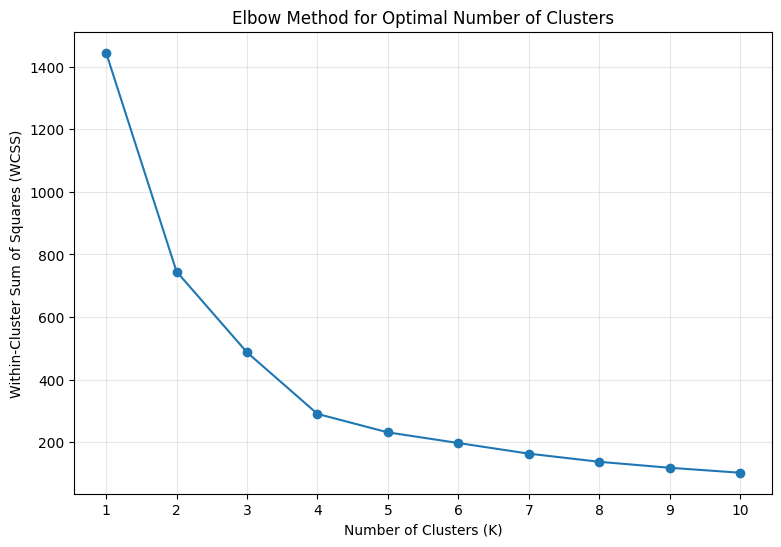

In [23]:
plt.figure(figsize=(9, 6))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(list(k_values))

plt.grid(alpha=0.3)
plt.show()

### Elbow Method Interpretation

The larger the number of clusters the smaller the WCSS. The improvement is clearly decreased after about 4 clusters and the curve levels off.

Based on the above, the Elbow Method recommends that K = 4 be considered a good choice for a balance between the cluster compactness and the complexity of the model.

## 11. Validate the Number of Clusters Using Silhouette Analysis

Silhouette Scores are computed for k ∈ {2, 3, ..., 10} to support the selection of the cluster.

The Silhouette Score compares the similarity of observations to the other observations in the cluster with the similarity of observations in the neighbouring cluster. Larger values correspond to better separation and cohesion of clusters.


In [25]:
# Calculate Silhouette Scores for K = 2 to K = 10

silhouette_k_values = range(2, 11)
silhouette_scores = []

for k in silhouette_k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    silhouette_scores.append(score)

# Create results table
silhouette_results = pd.DataFrame({
    'Number_of_Clusters': list(silhouette_k_values),
    'Silhouette_Score': silhouette_scores
})

silhouette_results.round(3)

,Number_of_Clusters,Silhouette_Score
0,2,0.438
1,3,0.442
2,4,0.472
3,5,0.441
4,6,0.427
5,7,0.424
6,8,0.427
7,9,0.435
8,10,0.431


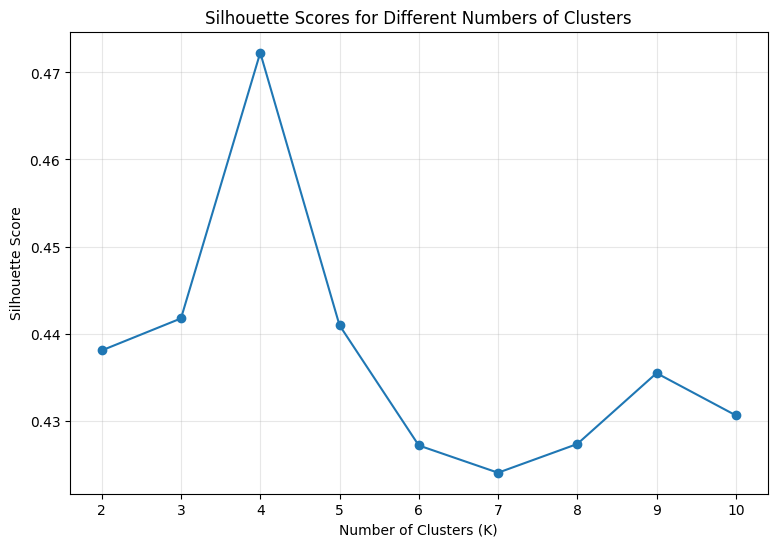

In [26]:
plt.figure(figsize=(9, 6))

plt.plot(
    list(silhouette_k_values),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Scores for Different Numbers of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(silhouette_k_values))

plt.grid(alpha=0.3)
plt.show()

### Silhouette Analysis Interpretation

The highest Silhouette Score is achieved for the 4-cluster solution at around 0.47. This is an independent verification of the Elbow Method result.

With the Elbow Method and Silhouette Analysis, four clusters are chosen to be finalized with the K-Means model.


## 12. Train the Final K-Means Clustering Model

The resulting K-Means model is trained with four clusters, based on the Elbow Method and Silhouette Analysis.

The random_state value is a fixed value to ensure repeatability of the analysis.

In [27]:
# Build the final K-Means model using four clusters
final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train the model and assign every customer to a cluster
df['Cluster'] = final_kmeans.fit_predict(X_scaled)

print("Final K-Means model trained successfully.")

Final K-Means model trained successfully.


In [28]:
df[['tenure', 'MonthlyCharges', 'Cluster']].head(10)

,tenure,MonthlyCharges,Cluster
0,1,25,0
1,41,25,3
2,52,19,3
3,1,76,2
4,67,51,3
5,68,90,1
6,23,77,2
7,72,72,1
8,70,104,1
9,1,19,0


## 13. Examine Cluster Sizes

Customers are assigned to each cluster and the number and percentage of each cluster are calculated to provide an indication of the distribution of the customer population across the identified clusters.

In [29]:
cluster_counts = df['Cluster'].value_counts().sort_index()

cluster_percentages = (
    df['Cluster']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

cluster_size_table = pd.DataFrame({
    'Customer_Count': cluster_counts,
    'Customer_Percentage': cluster_percentages
})

cluster_size_table.round(2)

,Customer_Count,Customer_Percentage
Cluster,,
0,1704,24.19
1,1930,27.40
2,2245,31.88
3,1164,16.53


## 14. Interpret the Customer Clusters

The clusters are described by the average (mean) holding period and average (mean) monthly charge. By "cluster averages," the technical K-Means groups can be mapped onto segments of customers with recognizable attributes.

In [30]:
cluster_profile = (
    df.groupby('Cluster')
      .agg(
          Customer_Count=('Cluster', 'size'),
          Average_Tenure=('tenure', 'mean'),
          Average_MonthlyCharges=('MonthlyCharges', 'mean')
      )
)

cluster_profile['Customer_Percentage'] = (
    cluster_profile['Customer_Count'] / len(df) * 100
)

cluster_profile.round(2)

,Customer_Count,Average_Tenure,Average_MonthlyCharges,Customer_Percentage
Cluster,,,,
0,1704,10.26,32.10,24.19
1,1930,58.97,93.03,27.40
2,2245,15.03,81.05,31.88
3,1164,54.07,34.27,16.53


In [31]:
# Calculate the median values of the original variables
tenure_median = df['tenure'].median()
charges_median = df['MonthlyCharges'].median()

# Create a dictionary to hold meaningful cluster names
cluster_name_mapping = {}

for cluster_number, row in cluster_profile.iterrows():

    # Determine tenure category
    if row['Average_Tenure'] < tenure_median:
        tenure_label = "Newer"
    else:
        tenure_label = "Loyal"

    # Determine monthly-charge category
    if row['Average_MonthlyCharges'] < charges_median:
        spending_label = "Low-Spend"
    else:
        spending_label = "High-Spend"

    cluster_name_mapping[cluster_number] = (
        tenure_label + " " + spending_label + " Customers"
    )

print(cluster_name_mapping)

{0: 'Newer Low-Spend Customers', 1: 'Loyal High-Spend Customers', 2: 'Newer High-Spend Customers', 3: 'Loyal Low-Spend Customers'}


In [32]:
# Add meaningful segment labels to the dataset
df['Customer_Segment'] = df['Cluster'].map(cluster_name_mapping)

df[
    ['tenure', 'MonthlyCharges', 'Cluster', 'Customer_Segment']
].head(10)

,tenure,MonthlyCharges,Cluster,Customer_Segment
0,1,25,0,Newer Low-Spend Customers
1,41,25,3,Loyal Low-Spend Customers
2,52,19,3,Loyal Low-Spend Customers
3,1,76,2,Newer High-Spend Customers
4,67,51,3,Loyal Low-Spend Customers
5,68,90,1,Loyal High-Spend Customers
6,23,77,2,Newer High-Spend Customers
7,72,72,1,Loyal High-Spend Customers
8,70,104,1,Loyal High-Spend Customers
9,1,19,0,Newer Low-Spend Customers


In [33]:
segment_summary = (
    df.groupby('Customer_Segment')
      .agg(
          Customer_Count=('Customer_Segment', 'size'),
          Average_Tenure=('tenure', 'mean'),
          Average_MonthlyCharges=('MonthlyCharges', 'mean')
      )
)

segment_summary['Customer_Percentage'] = (
    segment_summary['Customer_Count'] / len(df) * 100
)

segment_summary = segment_summary[
    [
        'Customer_Count',
        'Customer_Percentage',
        'Average_Tenure',
        'Average_MonthlyCharges'
    ]
]

segment_summary.round(2)

,Customer_Count,Customer_Percentage,Average_Tenure,Average_MonthlyCharges
Customer_Segment,,,,
Loyal High-Spend Customers,1930,27.40,58.97,93.03
Loyal Low-Spend Customers,1164,16.53,54.07,34.27
Newer High-Spend Customers,2245,31.88,15.03,81.05
Newer Low-Spend Customers,1704,24.19,10.26,32.10


## 15. Examine Cluster Centroids

K-Means uses the centroids to represent each customer segment. The trained model was normalised on features, so the coordinates of the centroids are translated back into the original units (months of tenure and monthly charges).

In [34]:
# Convert cluster centres back from scaled values to original units
centroids_original = scaler.inverse_transform(
    final_kmeans.cluster_centers_
)

centroid_table = pd.DataFrame(
    centroids_original,
    columns=['Centroid_Tenure', 'Centroid_MonthlyCharges']
)

centroid_table['Cluster'] = centroid_table.index

centroid_table['Customer_Segment'] = (
    centroid_table['Cluster']
    .map(cluster_name_mapping)
)

centroid_table[
    [
        'Cluster',
        'Customer_Segment',
        'Centroid_Tenure',
        'Centroid_MonthlyCharges'
    ]
].round(2)

,Cluster,Customer_Segment,Centroid_Tenure,Centroid_MonthlyCharges
0,0,Newer Low-Spend Customers,10.26,32.10
1,1,Loyal High-Spend Customers,58.94,93.03
2,2,Newer High-Spend Customers,15.00,81.03
3,3,Loyal Low-Spend Customers,54.07,34.27


## 16. Visualise the Customer Segments

Tenure is plotted on the X-axis and monthly charges on the Y-axis of the final customer clusters. A simple way of understanding the position of each customer segment is to see the cluster centroids.

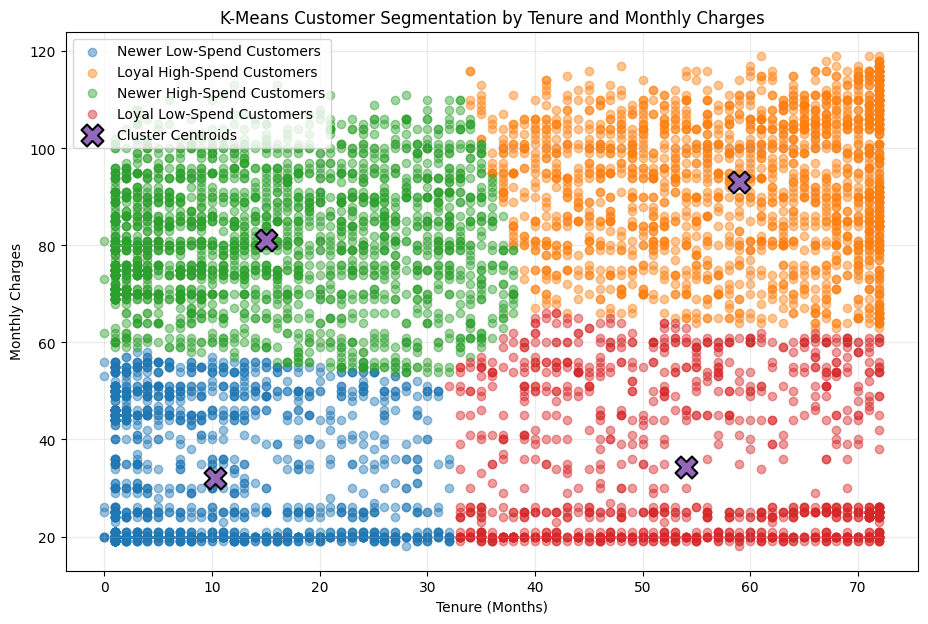

In [35]:
plt.figure(figsize=(11, 7))

# Plot customers separately for each cluster
for cluster_number in sorted(df['Cluster'].unique()):

    cluster_data = df[df['Cluster'] == cluster_number]

    plt.scatter(
        cluster_data['tenure'],
        cluster_data['MonthlyCharges'],
        alpha=0.45,
        label=cluster_name_mapping[cluster_number]
    )

# Plot original-scale cluster centroids
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker='X',
    s=250,
    edgecolor='black',
    linewidth=1.5,
    label='Cluster Centroids'
)

plt.title('K-Means Customer Segmentation by Tenure and Monthly Charges')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')

plt.legend()
plt.grid(alpha=0.25)

plt.show()

### Cluster Interpretation

The four-cluster solution groups the customers into different patterns of customer's longevity and the monthly expenditure:

Newer Low-Spend Customers: Customers that are relatively new and have comparatively low monthly spend.

Newer High-Spend Customers: Customers who have been relatively short on the market but have high monthly bills.

Loyal Low-Spend Customers: Customers that are loyal and have relatively low monthly spending.

Loyal High-Spend Customers: Customers that have been around for a long time and who spend a relatively high amount on their monthly bills.

The four clusters are very clearly distinguishable and are easily interpretable for telecommunications customer management purposes.

## 17. Post-Clustering Churn Analysis

Post-Clustering Churn Analysis
The Churn variable was not used to create the customer clusters. Once the segmentation without supervision is finished, the churn outcome for the different segments has been compared.

This post-clustering analysis can be used to identify any specific segments with higher observed churns and suggest higher retention efforts.


In [36]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [37]:
# Create a temporary numerical indicator for churn-rate calculation
df['Churn_Indicator'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

df[['Churn', 'Churn_Indicator']].head()

,Churn,Churn_Indicator
0,Yes,1
1,No,0
2,No,0
3,Yes,1
4,No,0


In [38]:
segment_churn_summary = (
    df.groupby('Customer_Segment')
      .agg(
          Customer_Count=('Customer_Segment', 'size'),
          Average_Tenure=('tenure', 'mean'),
          Average_MonthlyCharges=('MonthlyCharges', 'mean'),
          Churn_Rate=('Churn_Indicator', 'mean')
      )
)

segment_churn_summary['Customer_Percentage'] = (
    segment_churn_summary['Customer_Count'] / len(df) * 100
)

segment_churn_summary['Churn_Rate_Percent'] = (
    segment_churn_summary['Churn_Rate'] * 100
)

segment_churn_summary[
    [
        'Customer_Count',
        'Customer_Percentage',
        'Average_Tenure',
        'Average_MonthlyCharges',
        'Churn_Rate_Percent'
    ]
].round(2)

,Customer_Count,Customer_Percentage,Average_Tenure,Average_MonthlyCharges,Churn_Rate_Percent
Customer_Segment,,,,,
Loyal High-Spend Customers,1930,27.40,58.97,93.03,15.49
Loyal Low-Spend Customers,1164,16.53,54.07,34.27,4.90
Newer High-Spend Customers,2245,31.88,15.03,81.05,48.69
Newer Low-Spend Customers,1704,24.19,10.26,32.10,24.65


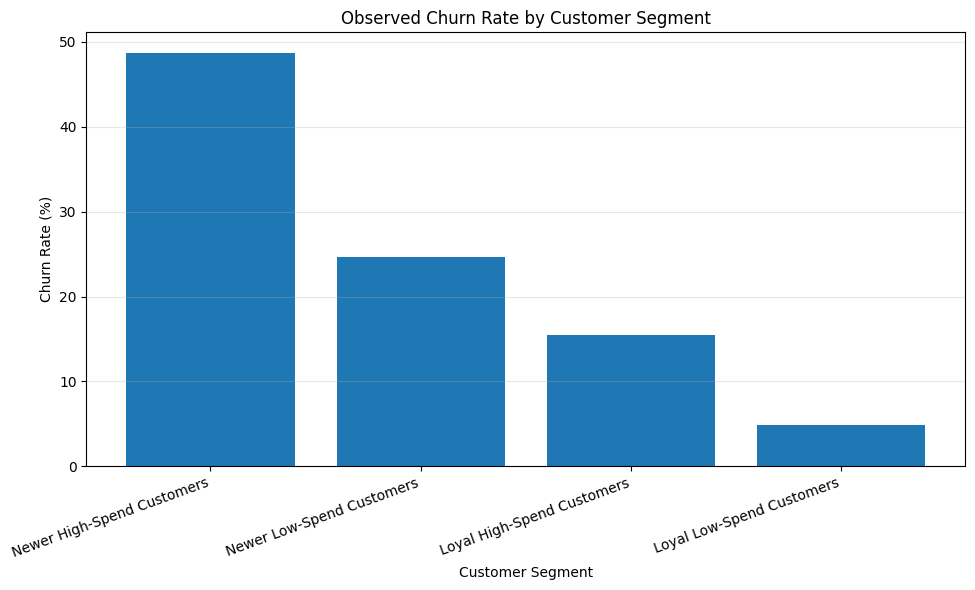

In [39]:
churn_plot_data = (
    segment_churn_summary['Churn_Rate_Percent']
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    churn_plot_data.index,
    churn_plot_data.values
)

plt.title('Observed Churn Rate by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Churn Analysis Interpretation

The post-clustering analysis shows that the customer segments differ significantly on churn observed.

The Newer High-Spend Customer segment has the highest churn rate at about 49%. These customers are paying relatively high monthly fees and are relatively short term.

Meanwhile, the Loyal Low Spend Customer segment has an observed churn rate of around 5%, reflecting the most stable segment.

The findings show that there is a relationship between the customers segments and the churn behaviour. The clustering analysis is still not a proof of a direct effect of tenure or monthly charges on churn.

## 18. Business Recommendations

Highest priority is given to newer High-Spend Customers.
This segment has the highest churn observed. In the initial customer life cycle, the company should look at proactive onboarding, early points of contact with customer service, tailored plan review, customer loyalty offers, and quality monitoring of customer service.

Newer Low-Spend Customers – Engagement Priority
The customers are of short duration and low monthly charges. Strategies on retention may target better initial engagement, informing service worth and providing suitable low-cost packages.

Loyal High Spenders – Guard High Value Relationships
These customers are long-term and charge high monthly. The company needs to maintain these valuable relationships with loyalty programs, priority customer service, service evaluations, and personalised retention programs.

Stable customers who don't spend much – Keep them loyal.Low Spend Customers – Keep them stable.
This segment shows long tenure, and has the lowest observed churn. The company should sustain good service levels and be able to identify appropriate service upgrade or cross selling opportunities on a selective basis, so as not to cause undue dissatisfaction.

## 19. Limitations and Challenges


The clustering results have to be interpreted with several limitations in mind:

Since these were set in the project requirement, the clustering model considers only tenure and monthly charges. Some other behaviour or service attributes might be used to add further segmentation information.

K-Means is based on Euclidean distance and works best if the clusters are compact and apart.

The number of clusters is a matter of analysis. While both the Elbow Method and Silhouette Analysis identified four clusters, other methods may have found different customer structure.

There is no unique identifier for the customer in the dataset and it is not possible to be confident that there are any repeated profiles identified as ‘duplicate customer records'.

The membership of a cluster may indicate statistical similarity, but not necessarily causal relationships between customer churn, tenure and monthly charges.

The results have been derived from the provided data set and must be tested with new and/or future customer data before implementing in large-scale operations.

## 20. Conclusion

The successful application of K-means clustering is used to segment the telecomms customers based on their tenure and their monthly charges. The data were validated and normalised prior to modelling and the results of the Elbow Method and the Silhouette Analysis indicated a 4-cluster solution.

This led to the segmentation of the results as Newer Low-Spend, Newer High-Spend, Loyal Low-Spend and Loyal High-Spend.

Post-clustering analysis revealed that the highest observed churn risk was with the segment of Newer High-Spend Customers and the highest stability was with Loyal Low-Spend Customers. The results offer a practical guide to differentiated retention strategies and targeted CRM.

## 21. Export the Final Clustered Dataset

This final clustering with meaningful labels for the resulting clusters and customer-segments is exported for further analysis and reporting.


In [40]:
# Remove temporary churn indicator before export if it is not required
final_clustered_dataset = df.drop(
    columns=['Churn_Indicator']
).copy()

# Save dataset
output_file = 'Telecom_Customer_Clustering_Results.csv'

final_clustered_dataset.to_csv(
    output_file,
    index=False
)

print("Final clustered dataset saved as:")
print(output_file)

Final clustered dataset saved as:
Telecom_Customer_Clustering_Results.csv


In [41]:
files.download('Telecom_Customer_Clustering_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>